# 04.2 Árbol de decisión: búsqueda de hiperparámetros (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en el `README.md` del experimento 1)

Es la misma búsqueda del experimento 1 con otra codificación de las variables y rangos más amplios. Qué cambia y por qué está explicado en el notebook de modelado del experimento 2.

Instrucciones:

- Misma validación que en el experimento 1: 5 grupos separados por animal, semilla `SEED` y `N_TRIALS` pruebas.
- Nombre de los archivos que se generan: `tree_clf` y `tree_reg`.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.pipeline import Pipeline

from config import SEED
from features import FEATURES, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]

c:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

Variables del experimento 2: las mismas 22 del experimento 1. Lo que cambia es cómo entran raza, color y ciudad (`CAT_HIGH`): con `build_preprocessor(..., cat_high_encoding="target")` se usa *target encoding* en lugar de one-hot. En clasificación, cada variable se convierte en 5 columnas (la proporción de cada salida en esa categoría); en regresión, en una sola (los días promedio, en log).

In [2]:
FEATURES_EXP2_CLF = FEATURES
FEATURES_EXP2_REG = FEATURES

print("El experimento 2 usa estas variables (las mismas que el experimento 1):")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables (las mismas que el experimento 1):
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


## Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `max_depth` | Cuántas preguntas seguidas puede hacer el árbol antes de decidir. | **2 a 60** (en el experimento 1 era 2 a 30) |
| `min_samples_leaf` | Cuántos animales tiene que haber como mínimo en cada hoja. | 1 a 500 (escala logarítmica) |
| `criterion` | Solo en clasificación. Cómo se mide qué tan buena es una pregunta: `gini` o `entropy`. | **nuevo**: `gini` o `entropy` |
| `class_weight` | Solo en clasificación. `balanced` da más peso a las clases pequeñas. | `None` o `balanced` |

En negrita, lo que cambia frente al experimento 1. Un árbol se entrena rápido, así que la búsqueda usa todos los datos, como en el experimento 1.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1.

Búsqueda de Árbol de decisión (clasificación): 20 pruebas con 63,681 filas y 57,564 animales.


Prueba 1/20: resultado 0.491 | mejor hasta ahora 0.491


Prueba 2/20: resultado 0.455 | mejor hasta ahora 0.491


Prueba 3/20: resultado 0.454 | mejor hasta ahora 0.491


Prueba 4/20: resultado 0.454 | mejor hasta ahora 0.491


Prueba 5/20: resultado 0.504 | mejor hasta ahora 0.504


... (12 outputs left out)

Prueba 18/20: resultado 0.505 | mejor hasta ahora 0.540


Prueba 19/20: resultado 0.337 | mejor hasta ahora 0.540


Prueba 20/20: resultado 0.445 | mejor hasta ahora 0.540

Mejores ajustes: {'max_depth': 11, 'min_samples_leaf': 9, 'criterion': 'entropy', 'class_weight': None}
Resultado de la búsqueda: macro-F1 = 0.540
- Los mejores valores quedaron dentro de los rangos probados.



Guardado en C:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\notebooks\04-hyperparameter-optimization-experiment-2: best_params/tree_clf.json, trials/tree_clf.csv y 2 gráficas en figures/


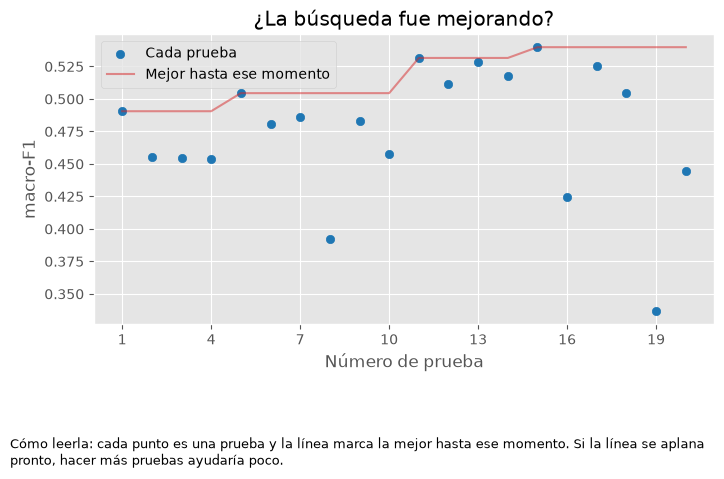

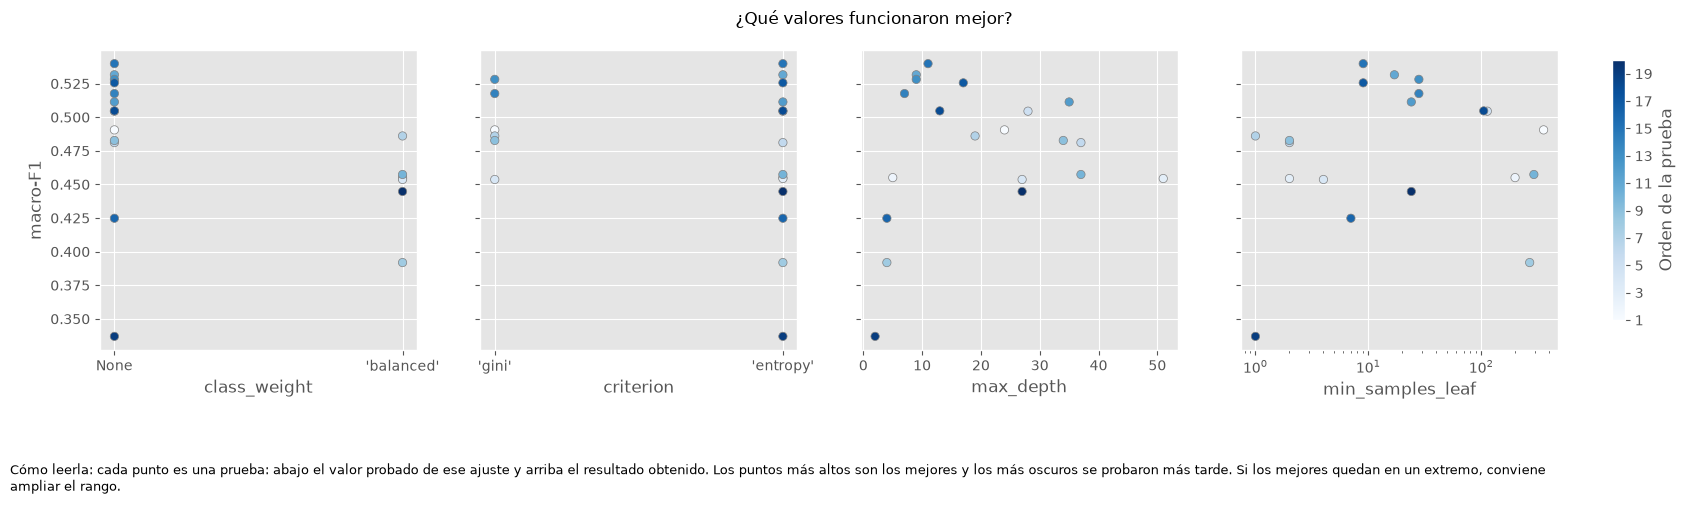

In [3]:
def make_pipe_clf(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF, cat_high_encoding="target")),
                     ("model", DecisionTreeClassifier(random_state=SEED, **params))])

def space_clf(trial):
    return {"max_depth": trial.suggest_int("max_depth", 2, 60),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 500, log=True),
            "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

PARAMS_HELP = {"max_depth": "Cuántas preguntas seguidas puede hacer el árbol (alto = más detalle).",
               "min_samples_leaf": "Mínimo de animales en cada decisión final (alto = más estable).",
               "criterion": "Cómo mide el árbol qué tan buena es una pregunta: gini o entropy.",
               "class_weight": "balanced da más peso a las clases pequeñas."}

study_clf = tune(
    "tree_clf", make_pipe_clf, space_clf, data[FEATURES_EXP2_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP2_CLF, model_label="Árbol de decisión", task_label="clasificación",
    params_help=PARAMS_HELP, n_trials=N_TRIALS)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log.

Búsqueda de Árbol de decisión (regresión): 20 pruebas con 27,073 filas y 24,720 animales.


Prueba 1/20: resultado 0.353 | mejor hasta ahora 0.353


Prueba 2/20: resultado 0.366 | mejor hasta ahora 0.366


Prueba 3/20: resultado 0.322 | mejor hasta ahora 0.366


Prueba 4/20: resultado 0.333 | mejor hasta ahora 0.366


Prueba 5/20: resultado 0.384 | mejor hasta ahora 0.384


... (12 outputs left out)

Prueba 18/20: resultado 0.368 | mejor hasta ahora 0.384


Prueba 19/20: resultado 0.382 | mejor hasta ahora 0.384


Prueba 20/20: resultado 0.256 | mejor hasta ahora 0.384

Mejores ajustes: {'max_depth': 37, 'min_samples_leaf': 67}
Resultado de la búsqueda: R² (en log) = 0.384
- Los mejores valores quedaron dentro de los rangos probados.



Guardado en C:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\notebooks\04-hyperparameter-optimization-experiment-2: best_params/tree_reg.json, trials/tree_reg.csv y 2 gráficas en figures/


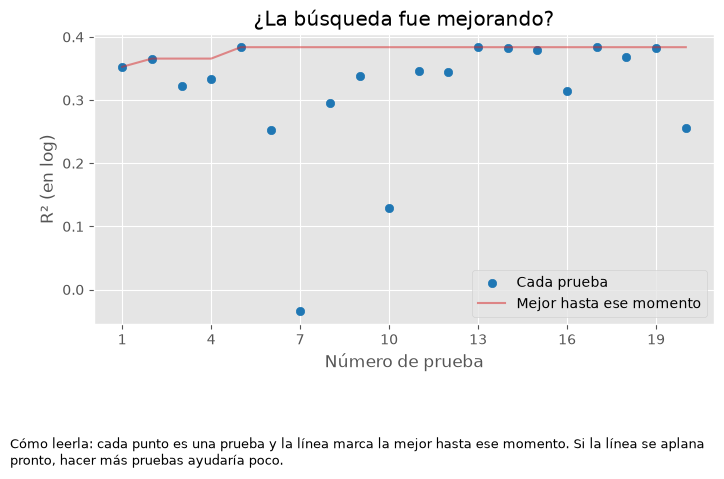

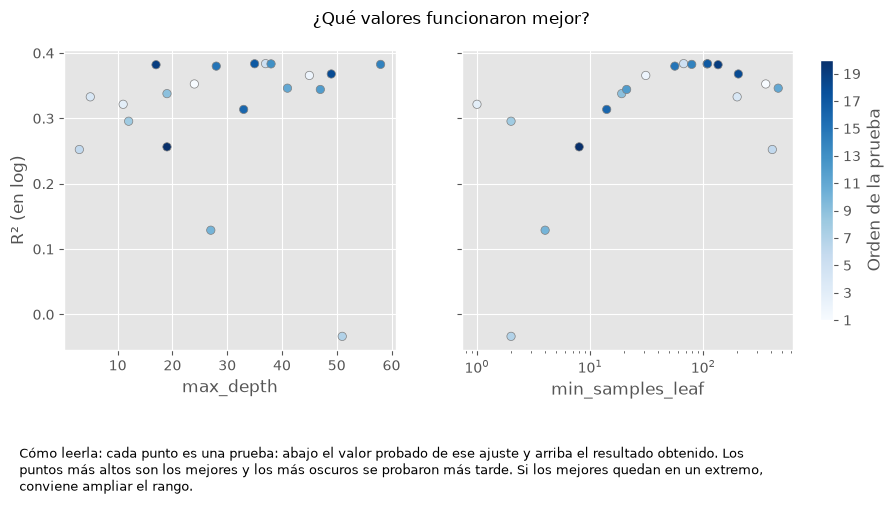

In [4]:
def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_REG, cat_high_encoding="target")),
                     ("model", DecisionTreeRegressor(random_state=SEED, **params))])

def space_reg(trial):
    return {"max_depth": trial.suggest_int("max_depth", 2, 60),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 500, log=True)}

study_reg = tune(
    "tree_reg", make_pipe_reg, space_reg, data.loc[adopted, FEATURES_EXP2_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP2_REG, model_label="Árbol de decisión", task_label="regresión",
    params_help=PARAMS_HELP, n_trials=N_TRIALS)